In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
rfm = pd.read_csv("rfm_output.csv")

In [26]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [28]:
print(rfm.shape)

(5878, 9)


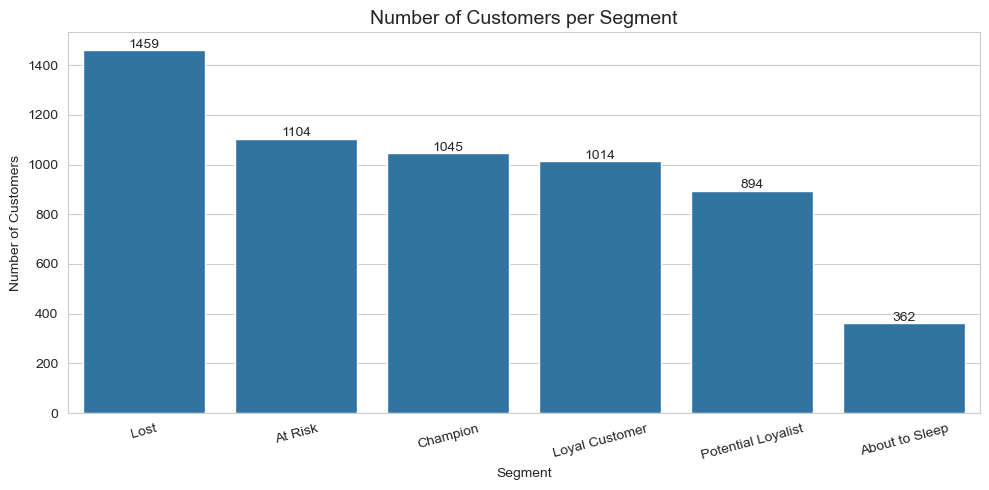

In [30]:
# Customer count per segment

segment_counts = rfm["Segment"].value_counts().reset_index()
segment_counts.columns = ["Segment", "Count"]

plt.figure(figsize=(10, 5))
sns.barplot(data=segment_counts, x="Segment", y="Count")

plt.title("Number of Customers per Segment", fontsize=14)
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

for i, row in segment_counts.iterrows():
    plt.text(i, row["Count"] + 10, str(row["Count"]), ha="center", fontsize=10)

plt.tight_layout()
plt.show()

In [31]:
# Revenue contribution per segment

segment_revenue = rfm.groupby("Segment")["Monetary"].sum().reset_index()
segment_revenue.columns = ["Segment", "Total Revenue"]
segment_revenue = segment_revenue.sort_values("Total Revenue", ascending=False)

total_rev = segment_revenue["Total Revenue"].sum()
segment_revenue["Revenue %"] = (segment_revenue["Total Revenue"] / total_rev * 100).round(1)

print(segment_revenue)

              Segment  Total Revenue  Revenue %
2            Champion   1.039926e+07       58.6
4      Loyal Customer   3.217209e+06       18.1
1             At Risk   2.180761e+06       12.3
3                Lost   1.046506e+06        5.9
5  Potential Loyalist   7.699532e+05        4.3
0      About to Sleep   1.297415e+05        0.7


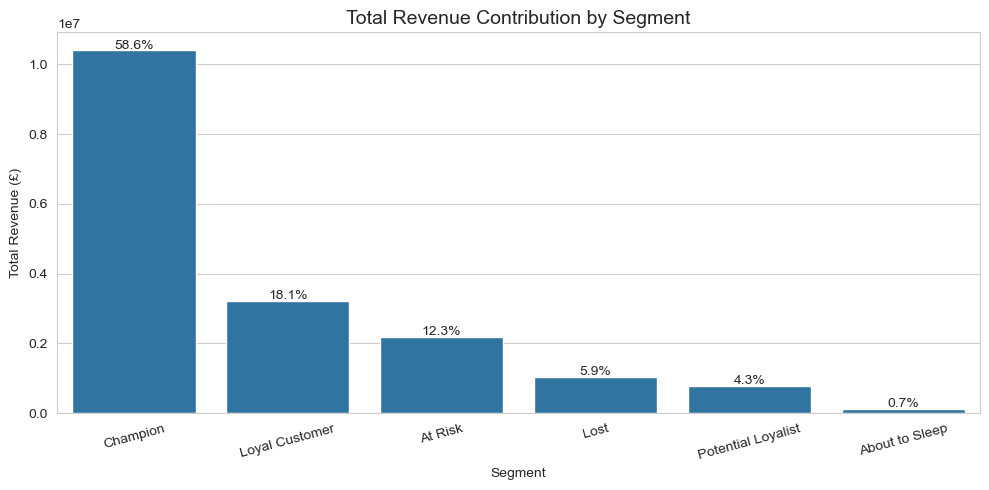

In [34]:
plt.figure(figsize=(10, 5))
sns.barplot(data=segment_revenue, x="Segment", y="Total Revenue")

plt.title("Total Revenue Contribution by Segment", fontsize=14)
plt.xlabel("Segment")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=15)

for i, row in segment_revenue.iterrows():
    plt.text(
        list(segment_revenue["Segment"]).index(row["Segment"]),
        row["Total Revenue"] + 50000,
        f"{row['Revenue %']}%",
        ha="center", fontsize=10
    )

plt.tight_layout()
plt.show()

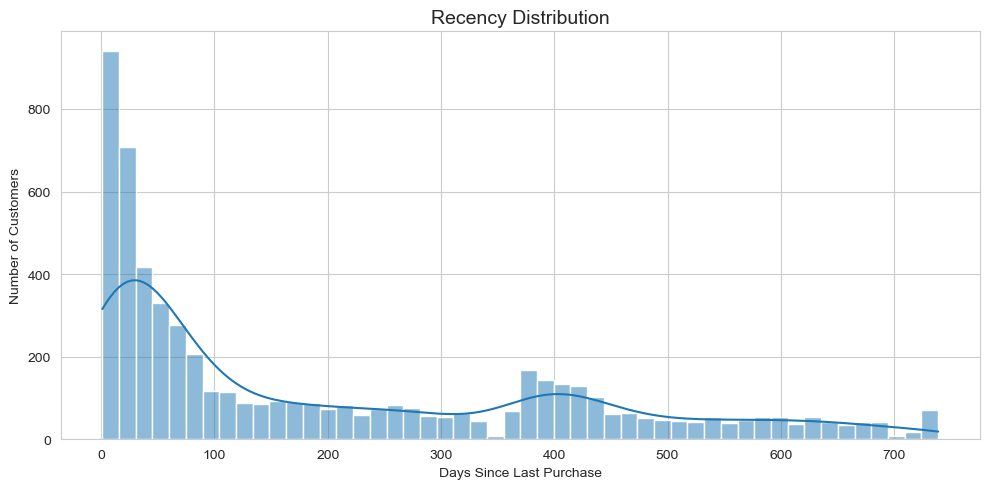

In [36]:
# Recency Distribution — How Many Days Since Last Purchase?

plt.figure(figsize=(10, 5))
sns.histplot(rfm["Recency"], bins=50, kde=True)

plt.title("Recency Distribution", fontsize=14)
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

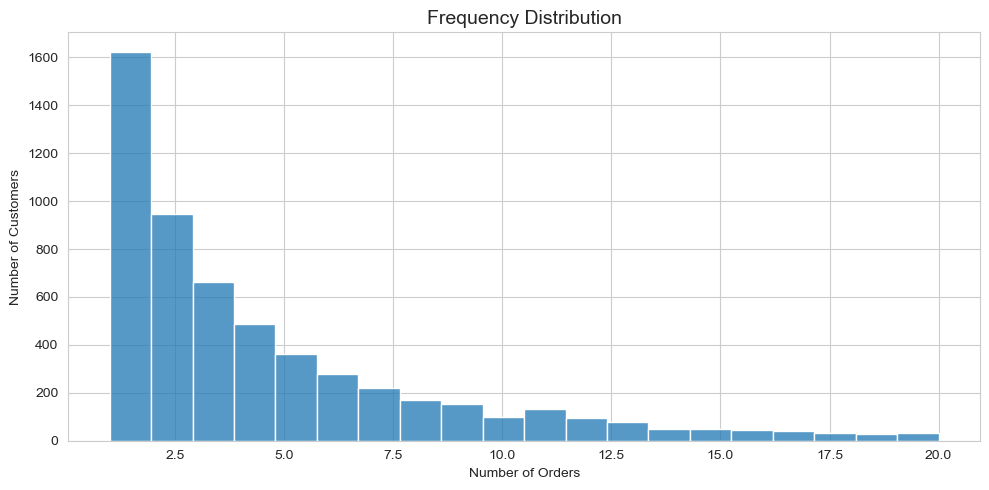

In [38]:
# Frequency Distribution — How Many Orders per Customer?

plt.figure(figsize=(10, 5))
sns.histplot(rfm[rfm["Frequency"] <= 20]["Frequency"], bins=20, kde=False)

plt.title("Frequency Distribution", fontsize=14)
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

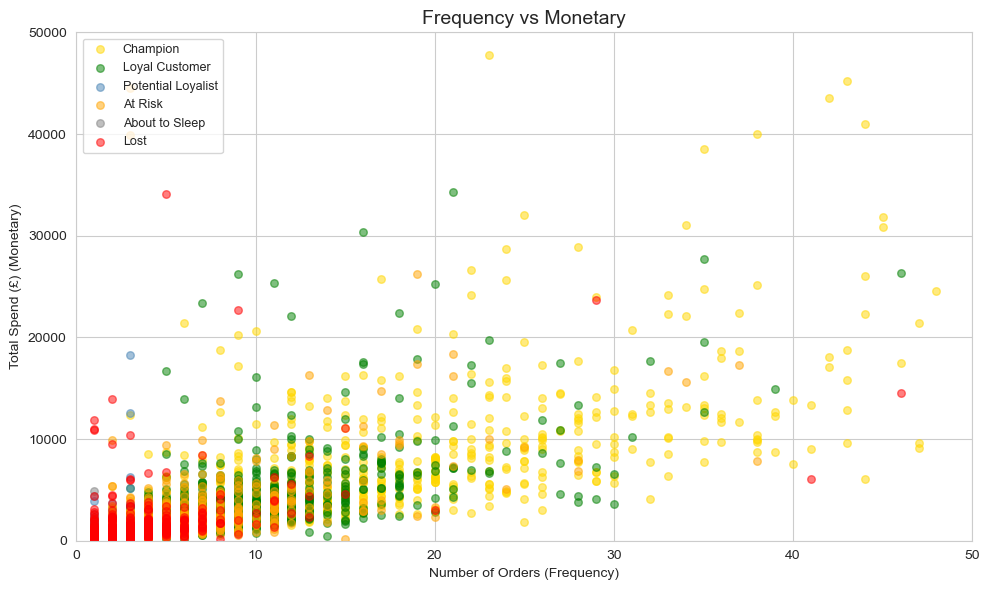

In [40]:
# Frequency vs Monetary — Who Are the High-Value Customers?

plt.figure(figsize=(10, 6))

segment_colors = {
    "Champion": "gold",
    "Loyal Customer": "green",
    "Potential Loyalist": "steelblue",
    "At Risk": "orange",
    "About to Sleep": "gray",
    "Lost": "red"
}

for segment, color in segment_colors.items():
    subset = rfm[rfm["Segment"] == segment]
    plt.scatter(subset["Frequency"], subset["Monetary"],
                label=segment, color = color, alpha=0.5, s=30)

plt.title("Frequency vs Monetary", fontsize=14)
plt.xlabel("Number of Orders (Frequency)")
plt.ylabel("Total Spend (£) (Monetary)")
plt.legend(loc="upper left", fontsize=9)
plt.xlim(0, 50)
plt.ylim(0, 50000)

plt.tight_layout()
plt.show()

In [42]:
total_customers = len(rfm)
champion_count = len(rfm[rfm["Segment"] == "Champion"])
lost_count = len(rfm[rfm["Segment"] == "Lost"])
at_risk_count = len(rfm[rfm["Segment"] == "At Risk"])

champion_revenue = rfm[rfm["Segment"] == "Champion"]["Monetary"].sum()
total_revenue = rfm["Monetary"].sum()
champion_rev_pct = round(champion_revenue / total_revenue * 100, 1)

churn_risk = lost_count + at_risk_count
churn_pct = round(churn_risk / total_customers * 100, 1)

print(f"Total Customers: {total_customers}")
print(f"Champions: {champion_count} ({round(champion_count/total_customers*100,1)}% of customers)")
print(f"Champion Revenue: £{round(champion_revenue,2)} ({champion_rev_pct}% of total revenue)")
print(f"Customers at churn risk (Lost + At Risk): {churn_risk} ({churn_pct}%)")
print(f"Total Revenue in dataset: £{round(total_revenue,2)}")

Total Customers: 5878
Champions: 1045 (17.8% of customers)
Champion Revenue: £10399258.12 (58.6% of total revenue)
Customers at churn risk (Lost + At Risk): 2563 (43.6%)
Total Revenue in dataset: £17743429.18
